In [236]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [237]:
df = pd.read_csv("fifa_players.csv")

Data Exploration

In [238]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17954 entries, 0 to 17953
Data columns (total 51 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   name                           17954 non-null  object 
 1   full_name                      17954 non-null  object 
 2   birth_date                     17954 non-null  object 
 3   age                            17954 non-null  int64  
 4   height_cm                      17954 non-null  float64
 5   weight_kgs                     17954 non-null  float64
 6   positions                      17954 non-null  object 
 7   nationality                    17954 non-null  object 
 8   overall_rating                 17954 non-null  int64  
 9   potential                      17954 non-null  int64  
 10  value_euro                     17699 non-null  float64
 11  wage_euro                      17708 non-null  float64
 12  preferred_foot                 17954 non-null 

In [239]:
df.duplicated().sum()

0

In [240]:
df.describe().round(2)

,age,height_cm,weight_kgs,overall_rating,potential,value_euro,wage_euro,international_reputation(1-5),weak_foot(1-5),skill_moves(1-5),...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
count,17954.00,17954.00,17954.00,17954.00,17954.00,1.769900e+04,17708.00,17954.00,17954.00,17954.00,...,17954.00,17954.00,17954.00,17954.00,17954.00,17954.00,17954.00,17954.00,17954.00,17954.00
mean,25.57,174.95,75.30,66.24,71.43,2.479280e+06,9902.13,1.11,2.95,2.36,...,46.85,55.82,46.66,49.86,53.41,48.36,58.68,47.16,47.73,45.71
std,4.71,14.03,7.08,6.96,6.13,5.687014e+06,21995.59,0.39,0.66,0.76,...,19.43,17.39,20.75,19.69,14.16,15.81,11.63,20.04,21.67,21.29
min,17.00,152.40,49.90,47.00,48.00,1.000000e+04,1000.00,1.00,1.00,1.00,...,3.00,11.00,3.00,2.00,10.00,5.00,12.00,3.00,2.00,3.00
25%,22.00,154.94,69.90,62.00,67.00,3.250000e+05,1000.00,1.00,3.00,2.00,...,32.00,44.00,26.00,38.00,44.00,38.00,51.00,30.00,27.00,24.00
50%,25.00,175.26,74.80,66.00,71.00,7.000000e+05,3000.00,1.00,3.00,2.00,...,51.00,59.00,52.00,55.00,55.00,49.00,60.00,52.50,55.00,52.00
75%,29.00,185.42,79.80,71.00,75.00,2.100000e+06,9000.00,1.00,3.00,3.00,...,62.00,69.00,64.00,64.00,64.00,60.00,67.00,64.00,66.00,64.00
max,46.00,205.74,110.20,94.00,95.00,1.105000e+08,565000.00,5.00,5.00,5.00,...,94.00,95.00,92.00,95.00,94.00,92.00,96.00,94.00,93.00,90.00


In [241]:
df.isna().sum()

name                                 0
full_name                            0
birth_date                           0
age                                  0
height_cm                            0
weight_kgs                           0
positions                            0
nationality                          0
overall_rating                       0
potential                            0
value_euro                         255
wage_euro                          246
preferred_foot                       0
international_reputation(1-5)        0
weak_foot(1-5)                       0
skill_moves(1-5)                     0
body_type                            0
release_clause_euro               1837
national_team                    17097
national_rating                  17097
national_team_position           17097
national_jersey_number           17097
crossing                             0
finishing                            0
heading_accuracy                     0
short_passing            

In [242]:
df = df.drop(columns=["national_team", "national_rating", "national_team_position", "national_jersey_number", "birth_date", "release_clause_euro"])

In [243]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17954 entries, 0 to 17953
Data columns (total 45 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   name                           17954 non-null  object 
 1   full_name                      17954 non-null  object 
 2   age                            17954 non-null  int64  
 3   height_cm                      17954 non-null  float64
 4   weight_kgs                     17954 non-null  float64
 5   positions                      17954 non-null  object 
 6   nationality                    17954 non-null  object 
 7   overall_rating                 17954 non-null  int64  
 8   potential                      17954 non-null  int64  
 9   value_euro                     17699 non-null  float64
 10  wage_euro                      17708 non-null  float64
 11  preferred_foot                 17954 non-null  object 
 12  international_reputation(1-5)  17954 non-null 

In [244]:
df["value_euro"] = df["value_euro"].fillna(df["value_euro"].mean())
df["wage_euro"] = df["wage_euro"].fillna(df["wage_euro"].mean())

In [245]:
df.isna().sum()

name                             0
full_name                        0
age                              0
height_cm                        0
weight_kgs                       0
positions                        0
nationality                      0
overall_rating                   0
potential                        0
value_euro                       0
wage_euro                        0
preferred_foot                   0
international_reputation(1-5)    0
weak_foot(1-5)                   0
skill_moves(1-5)                 0
body_type                        0
crossing                         0
finishing                        0
heading_accuracy                 0
short_passing                    0
volleys                          0
dribbling                        0
curve                            0
freekick_accuracy                0
long_passing                     0
ball_control                     0
acceleration                     0
sprint_speed                     0
agility             

In [246]:
df['age'].describe()

count    17954.000000
mean        25.565445
std          4.705708
min         17.000000
25%         22.000000
50%         25.000000
75%         29.000000
max         46.000000
Name: age, dtype: float64

In [247]:
df['age'].value_counts().sort_index()

age
17     163
18     509
19     957
20    1145
21    1347
22    1360
23    1315
24    1303
25    1304
26    1248
27    1318
28    1118
29     979
30     893
31     845
32     628
33     465
34     322
35     354
36     165
37      99
38      56
39      31
40      15
41      10
42       2
44       1
45       1
46       1
Name: count, dtype: int64

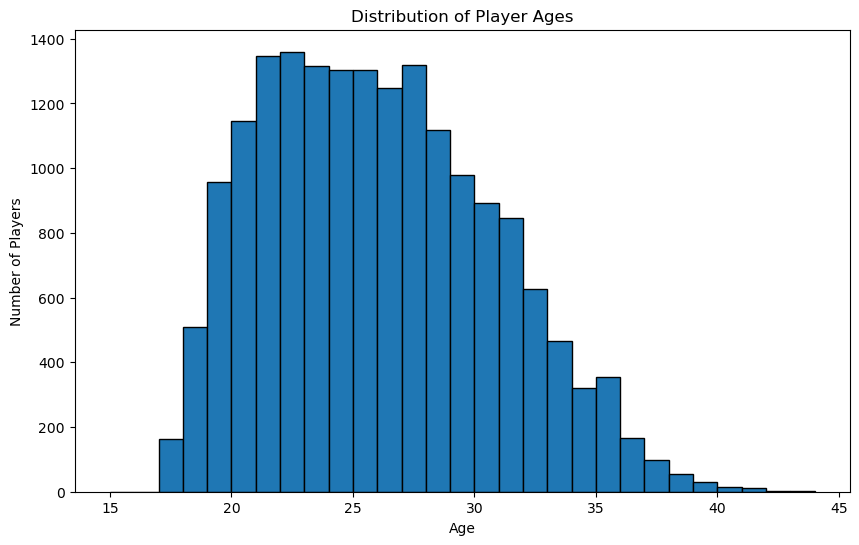

In [248]:

plt.figure(figsize=(10, 6))

plt.hist(df['age'], bins=range(15, 45), edgecolor='black')

plt.title('Distribution of Player Ages')
plt.xlabel('Age')
plt.ylabel('Number of Players')

plt.show()

In [249]:
df['overall_rating'].describe()

count    17954.000000
mean        66.240169
std          6.963730
min         47.000000
25%         62.000000
50%         66.000000
75%         71.000000
max         94.000000
Name: overall_rating, dtype: float64

In [250]:
df['overall_rating'].value_counts().sort_index()

overall_rating
47      21
48      33
49      45
50      98
51     120
52     165
53     227
54     255
55     276
56     331
57     408
58     458
59     484
60     621
61     691
62     849
63     963
64    1057
65    1041
66    1088
67    1074
68    1071
69     911
70     930
71     804
72     736
73     605
74     560
75     477
76     373
77     288
78     175
79     178
80     134
81      83
82     100
83      72
84      44
85      31
86      17
87      18
88      16
89      10
90       8
91       5
92       1
94       2
Name: count, dtype: int64

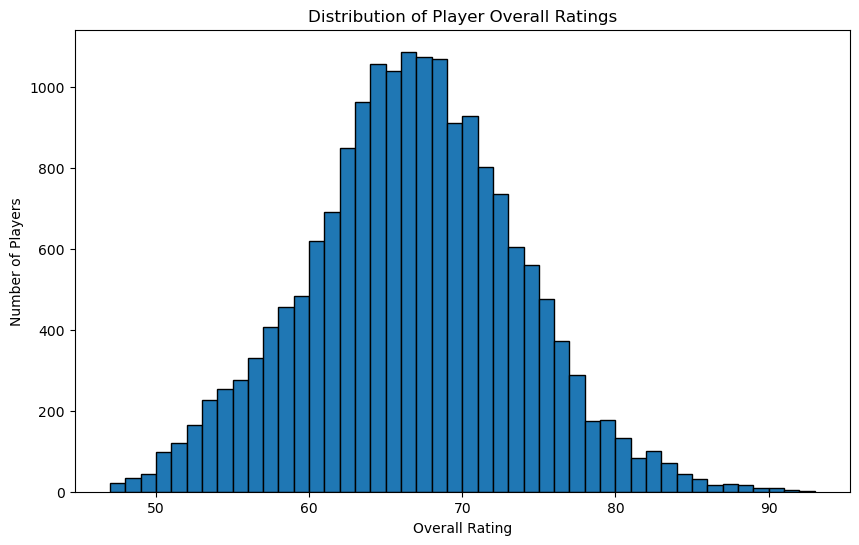

In [251]:

plt.figure(figsize=(10, 6))

plt.hist(
    df['overall_rating'],
    bins=range(
        int(df['overall_rating'].min()),
        int(df['overall_rating'].max())
    ),
    edgecolor='black'
)

plt.title('Distribution of Player Overall Ratings')
plt.xlabel('Overall Rating')
plt.ylabel('Number of Players')

plt.show()

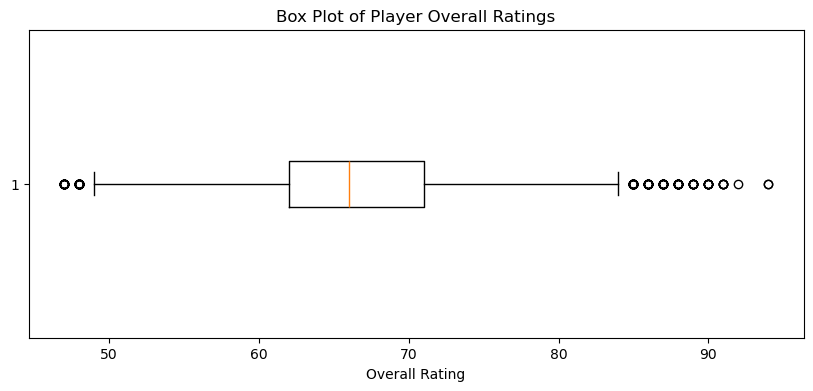

In [252]:
plt.figure(figsize=(10, 4))

plt.boxplot(df['overall_rating'], vert=False)

plt.title('Box Plot of Player Overall Ratings')
plt.xlabel('Overall Rating')

plt.show()

In [253]:
positions = df['positions'].dropna().str.split(', ')

In [254]:
positions.value_counts()

positions
[CB]              2243
[GK]              2065
[ST]              1747
[CM]               764
[CDM,CM]           709
                  ... 
[LB,LM,CB]           1
[CF,CM,ST]           1
[CB,ST]              1
[RB,ST]              1
[CAM,CM,RW,RM]       1
Name: count, Length: 890, dtype: int64

Overall rating vs. potential

In [255]:
df[['overall_rating', 'potential']].corr()

,overall_rating,potential
overall_rating,1.000000,0.647249
potential,0.647249,1.000000


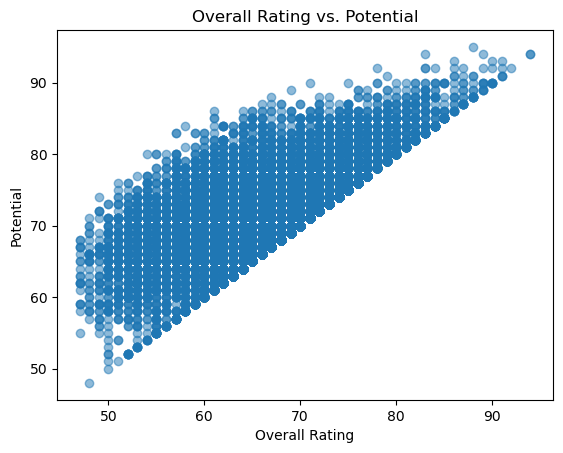

In [256]:
plt.scatter(
    df['overall_rating'],
    df['potential'],
    alpha=0.5
)

plt.title('Overall Rating vs. Potential')
plt.xlabel('Overall Rating')
plt.ylabel('Potential')

plt.show()

In [257]:
df['potential_gap'] = df['potential'] - df['overall_rating']

In [258]:

df[['name', 'overall_rating', 'potential', 'potential_gap']] \
    .sort_values('potential_gap', ascending=False) \
    .head(10)

,name,overall_rating,potential,potential_gap
5433,M. Daramy,54,80,26
6126,S. Sohm,57,83,26
6140,T. Parrott,57,83,26
6495,J. von Moos,58,84,26
5655,B. Mumba,55,80,25
4546,J. García,55,80,25
4929,S. Spasov,49,74,25
7809,A. Riccardi,61,86,25
5049,H. Geelmuyden,51,76,25
7478,K. Hoever,61,85,24


In [259]:
df[['wage_euro', 'overall_rating']].corr()

,wage_euro,overall_rating
wage_euro,1.000000,0.574453
overall_rating,0.574453,1.000000


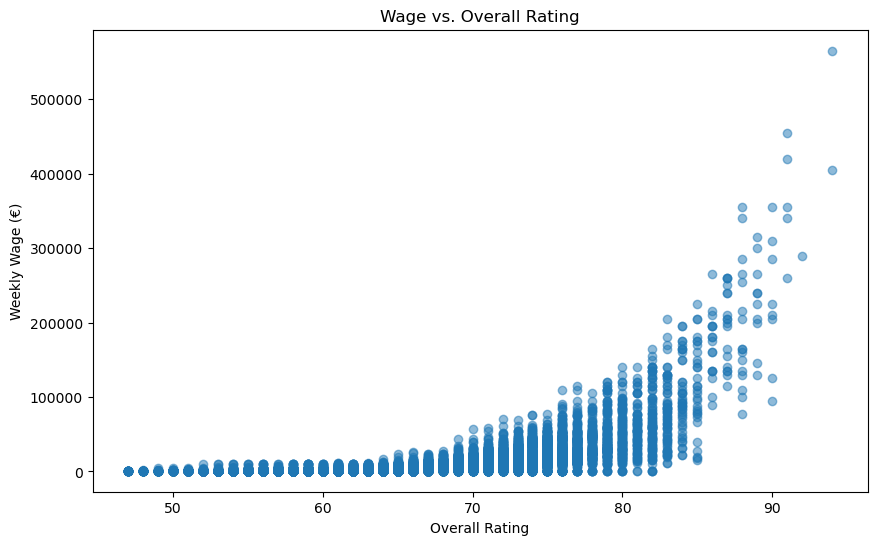

In [260]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['overall_rating'],
    df['wage_euro'],
    alpha=0.5
)

plt.title('Wage vs. Overall Rating')
plt.xlabel('Overall Rating')
plt.ylabel('Weekly Wage (€)')

plt.show()

Correlation Heatmap

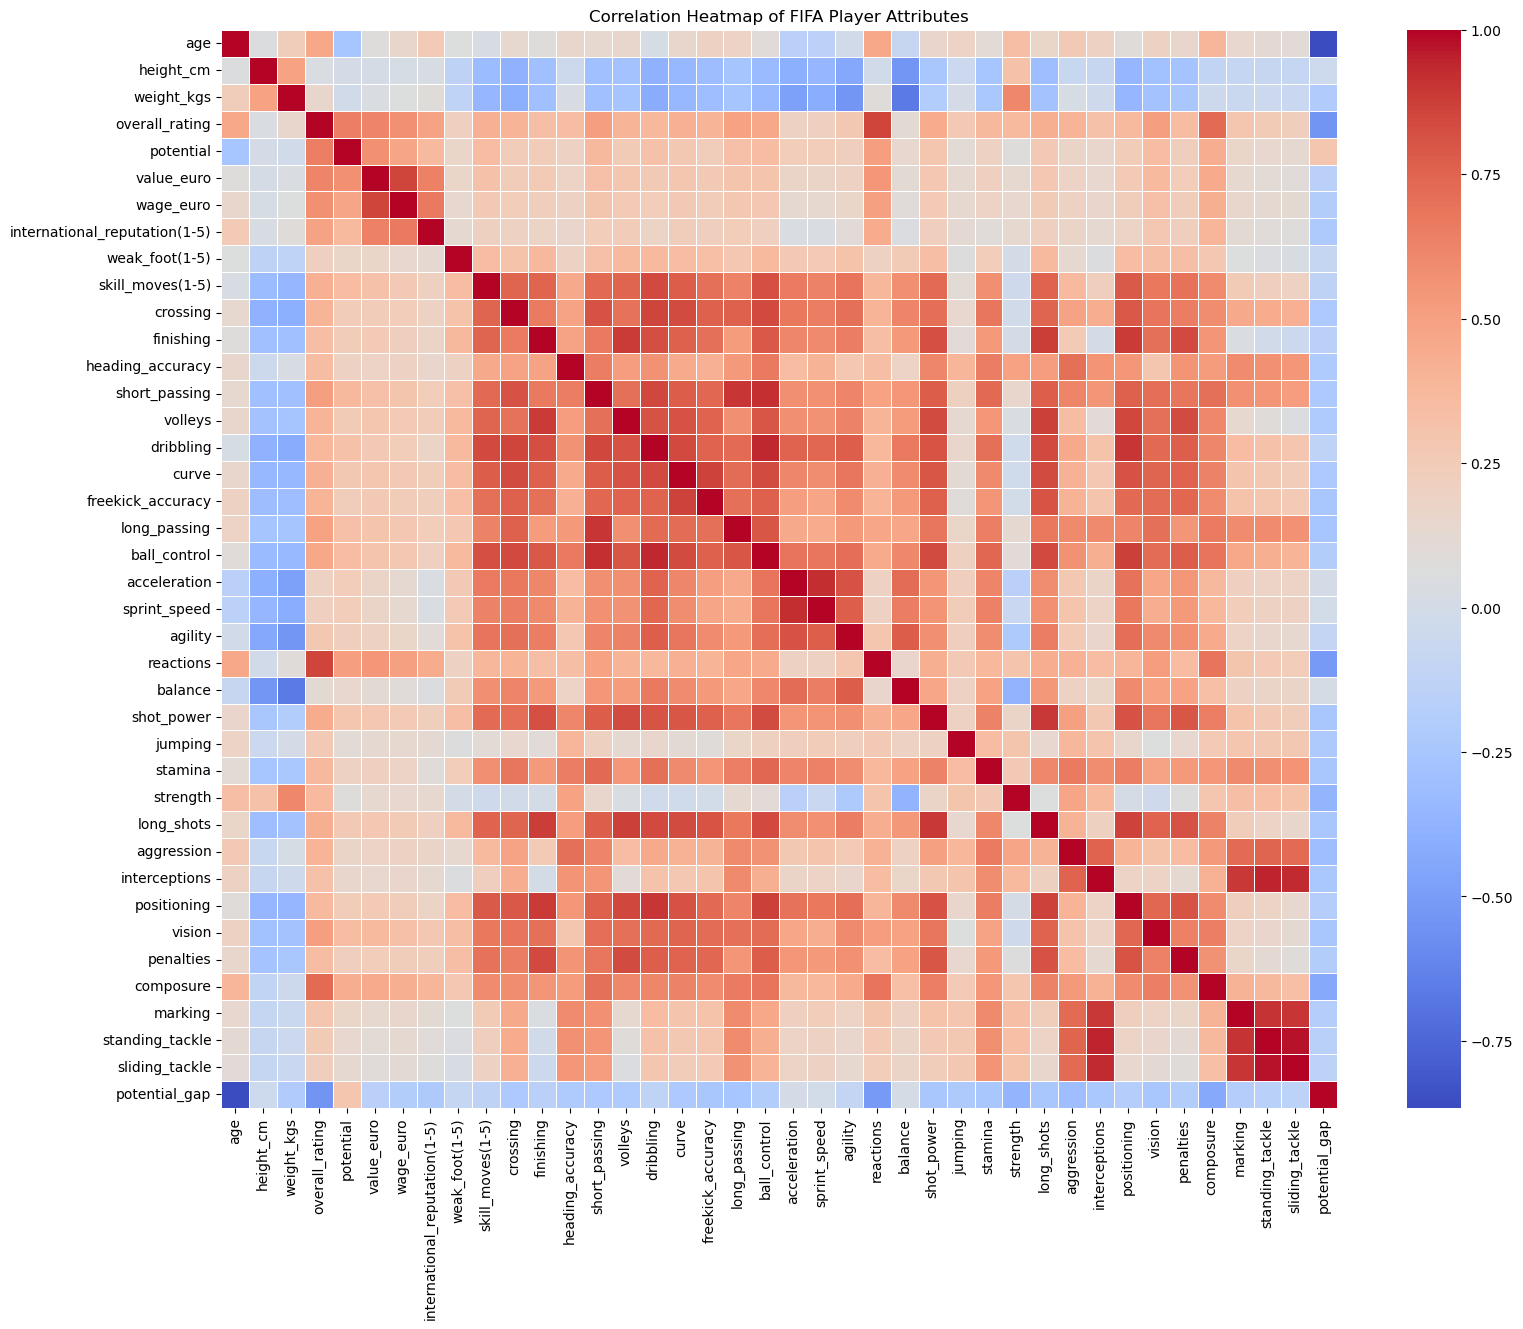

In [261]:
numeric_df = df.select_dtypes(include='number')

corr_matrix = numeric_df.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    annot=False,
    linewidths=0.5
)

plt.title('Correlation Heatmap of FIFA Player Attributes')
plt.show()

Data Analysis

In [262]:
average_rating = (
    df.groupby('nationality')['overall_rating']
    .mean()
    .sort_values(ascending=False)
)
average_rating

nationality
United Arab Emirates    77.000000
São Tomé & Príncipe     72.000000
Dominican Republic      72.000000
Oman                    72.000000
Mozambique              72.000000
                          ...    
Grenada                 59.500000
China PR                59.477273
Yemen                   58.000000
India                   57.966667
Indonesia               56.000000
Name: overall_rating, Length: 160, dtype: float64

In [263]:
top_10 = average_rating.head(10)
top_10

nationality
United Arab Emirates    77.000000
São Tomé & Príncipe     72.000000
Dominican Republic      72.000000
Oman                    72.000000
Mozambique              72.000000
Israel                  71.666667
Portugal                71.113433
Brazil                  71.051683
New Caledonia           71.000000
Libya                   71.000000
Name: overall_rating, dtype: float64

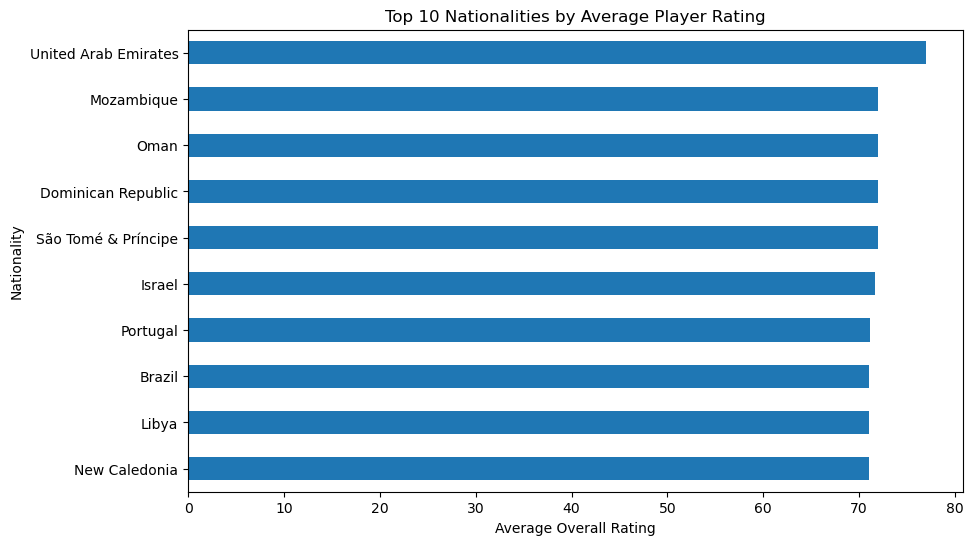

In [264]:
plt.figure(figsize=(10, 6))

top_10.sort_values().plot(kind='barh')

plt.title('Top 10 Nationalities by Average Player Rating')
plt.xlabel('Average Overall Rating')
plt.ylabel('Nationality')

plt.show()

In [265]:
nationality_stats = (
    df.groupby('nationality')['overall_rating']
    .agg(['mean', 'count'])
    .query('count > 100')
    .sort_values('mean', ascending=False)
)

nationality_stats

,mean,count
nationality,,
Portugal,71.113433,335
Brazil,71.051683,832
Uruguay,70.748148,135
Serbia,70.030534,131
Croatia,69.646617,133
Spain,69.614953,1070
Czech Republic,69.382353,102
Ivory Coast,69.156863,102
Italy,68.769466,655


In [266]:
nationality_stats = nationality_stats.rename(columns={
    'mean': 'average_rating',
    'count': 'number_of_players'
})

nationality_stats

,average_rating,number_of_players
nationality,,
Portugal,71.113433,335
Brazil,71.051683,832
Uruguay,70.748148,135
Serbia,70.030534,131
Croatia,69.646617,133
Spain,69.614953,1070
Czech Republic,69.382353,102
Ivory Coast,69.156863,102
Italy,68.769466,655


In [267]:
top_10_cleaned = nationality_stats.head(10)
top_10_cleaned 

,average_rating,number_of_players
nationality,,
Portugal,71.113433,335
Brazil,71.051683,832
Uruguay,70.748148,135
Serbia,70.030534,131
Croatia,69.646617,133
Spain,69.614953,1070
Czech Republic,69.382353,102
Ivory Coast,69.156863,102
Italy,68.769466,655


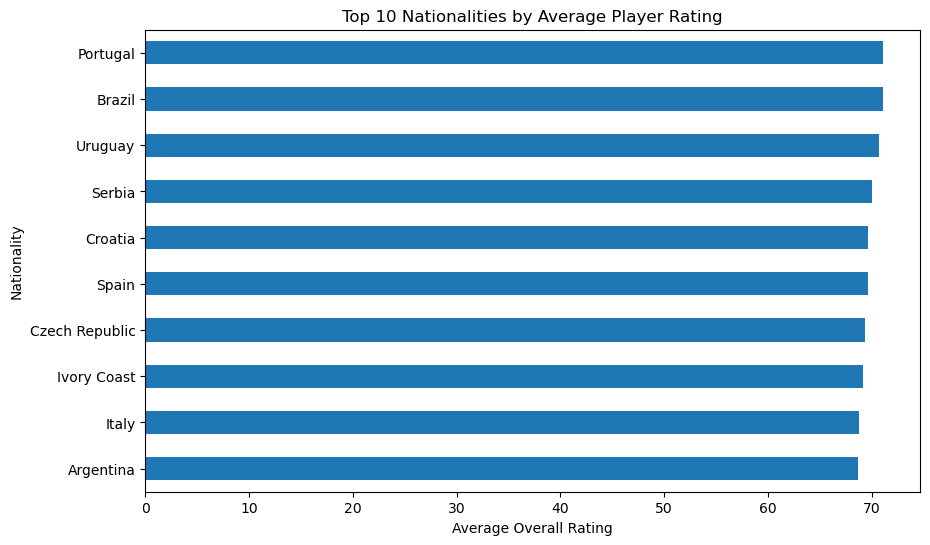

In [268]:
top_10_cleaned['average_rating'].sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Nationalities by Average Player Rating')
plt.xlabel('Average Overall Rating')
plt.ylabel('Nationality')
plt.show()

In [269]:
df_positions = df.assign(
    positions=df['positions'].str.split(',')
).explode('positions')



In [270]:
position_stats = (
    df_positions.groupby('positions')['overall_rating']
    .agg(['mean', 'count'])
    .sort_values('mean', ascending=False)
    .rename(columns={
        'mean': 'average_rating',
        'count': 'number_of_players'
    })
)
position_stats

,average_rating,number_of_players
positions,,
CF,68.715470,362
LW,68.028213,957
RW,67.984060,941
CAM,67.631121,2185
CDM,67.607262,2699
LWB,67.036789,299
LM,67.018643,2521
RM,67.011419,2452
RWB,66.990446,314


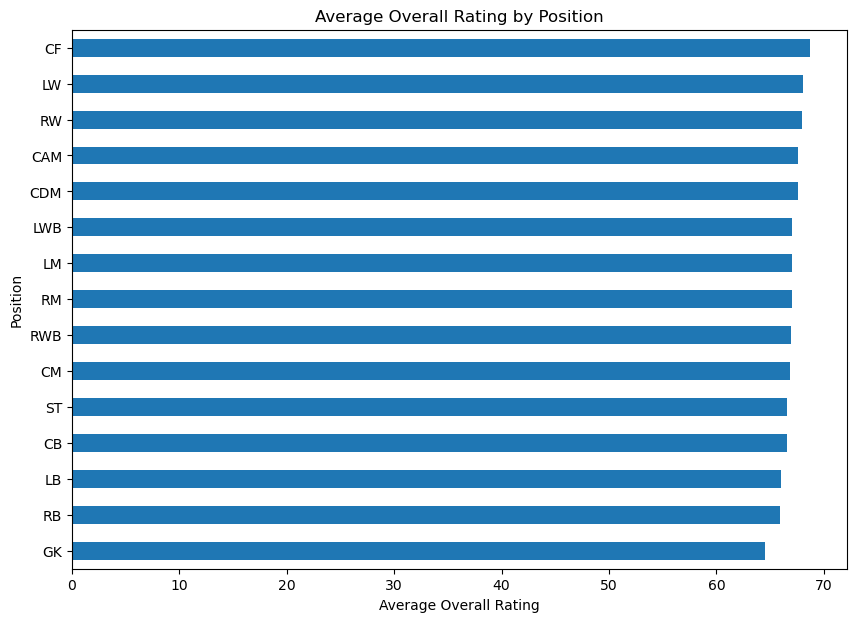

In [271]:
position_stats['average_rating'].sort_values().plot(
    kind='barh',
    figsize=(10, 7)
)

plt.title('Average Overall Rating by Position')
plt.xlabel('Average Overall Rating')
plt.ylabel('Position')
plt.show()

In [272]:
highest_paid = (
    df.sort_values('wage_euro', ascending=False)
    [['name', 'nationality', 'overall_rating', 'wage_euro']]
    .head(10)
)
highest_paid

,name,nationality,overall_rating,wage_euro
0,L. Messi,Argentina,94,565000.0
17938,L. Suárez,Uruguay,91,455000.0
17939,L. Modrić,Croatia,91,420000.0
17944,Cristiano Ronaldo,Portugal,94,405000.0
17941,K. De Bruyne,Belgium,91,355000.0
17934,T. Kroos,Germany,90,355000.0
17924,G. Bale,Wales,88,355000.0
17940,E. Hazard,Belgium,91,340000.0
17928,Coutinho,Brazil,88,340000.0
10,Sergio Busquets,Spain,89,315000.0


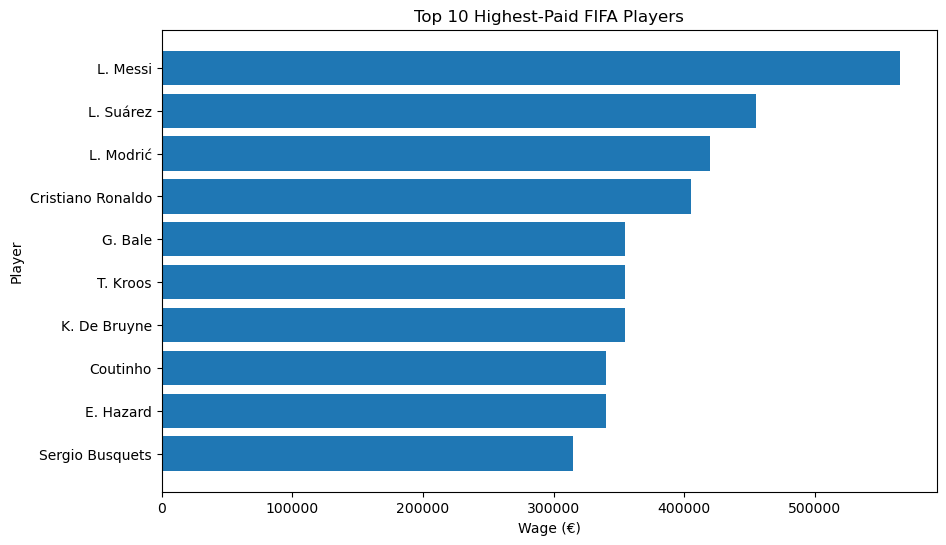

In [273]:
highest_paid = highest_paid.sort_values('wage_euro')

plt.figure(figsize=(10, 6))
plt.barh(highest_paid['name'], highest_paid['wage_euro'])

plt.title('Top 10 Highest-Paid FIFA Players')
plt.xlabel('Wage (€)')
plt.ylabel('Player')
plt.show()

In [277]:
highest_potential = (
    df.sort_values('potential', ascending=False)
    [['name', 'nationality', 'overall_rating', 'potential']]
    .head(10)
)


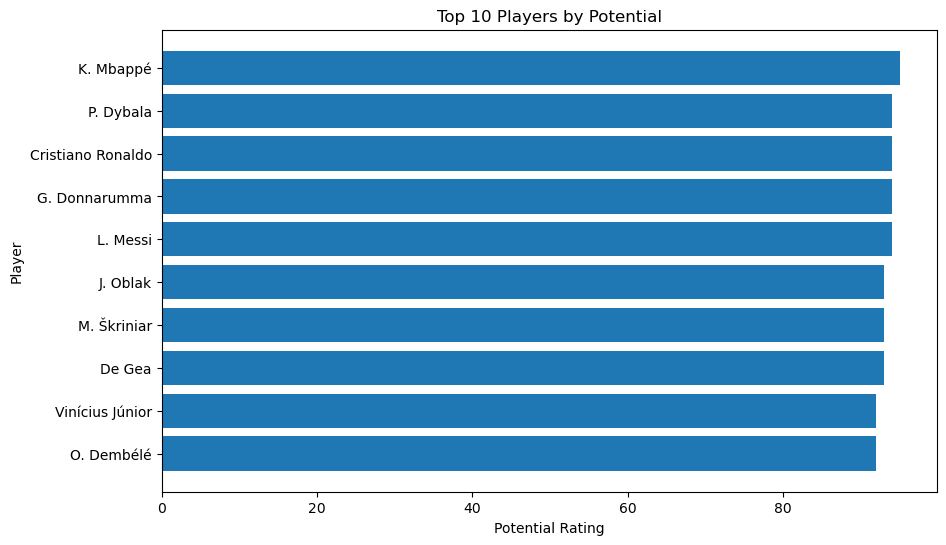

In [278]:

highest_potential = highest_potential.sort_values('potential')

plt.figure(figsize=(10, 6))
plt.barh(highest_potential['name'], highest_potential['potential'])

plt.title('Top 10 Players by Potential')
plt.xlabel('Potential Rating')
plt.ylabel('Player')

plt.show()